In [2]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from utils import data_handling, k_folds

/Users/salimelouahdani/anaconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data Import and Treatment

Importing Data

In [3]:
X = pd.read_csv('data/X_train.csv', index_col='ROW_ID')
Y = pd.read_csv('data/y_train.csv', index_col='ROW_ID')

In [19]:
X["ALLOCATION"].head()

ROW_ID
0    ALLOCATION_01
1    ALLOCATION_02
2    ALLOCATION_03
3    ALLOCATION_04
4    ALLOCATION_05
Name: ALLOCATION, dtype: object

In [29]:
import numpy as np
import pandas as pd

ret_cols = [f"RET_{i}" for i in range(1, 21)]


def find_next_row(X, shift=1):
    # for each row, find the row of the same allocation that comes `shift` days later
    # if B is the day after A, RET_2..RET_20 of B should be almost RET_1..RET_19 of A
    results = []

    for alloc in X["ALLOCATION"].unique():
        sub = X[X["ALLOCATION"] == alloc]
        R = sub[ret_cols].fillna(0).values

        later = R[:, shift:]
        earlier = R[:, :20 - shift]

        # center + normalize each row so that the dot product is the correlation
        later = later - later.mean(axis=1, keepdims=True)
        later = later / (np.linalg.norm(later, axis=1, keepdims=True) + 1e-12)
        earlier = earlier - earlier.mean(axis=1, keepdims=True)
        earlier = earlier / (np.linalg.norm(earlier, axis=1, keepdims=True) + 1e-12)

        corr = later @ earlier.T      # corr[s, p]: how well row s follows row p
        np.fill_diagonal(corr, -1)    # a row can't follow itself

        best = corr.argmax(axis=0)    # best successor of each row

        df = pd.DataFrame()
        df["ROW_ID"] = sub.index
        df["TS"] = sub["TS"].values
        df["ALLOCATION"] = alloc
        df["TS_next"] = sub["TS"].values[best]
        df["corr"] = corr[best, np.arange(len(sub))]
        results.append(df)

    return pd.concat(results, ignore_index=True)


links = find_next_row(X)
print(links["corr"].describe())

count    527073.000000
mean          0.981693
std           0.032805
min           0.433140
25%           0.980312
50%           0.991936
75%           0.996978
max           1.000000
Name: corr, dtype: float64


In [54]:
most_common_ts_next_by_ts = (
    links.groupby(["TS", "TS_next"])
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["TS", "count", "TS_next"], ascending=[True, False, True])
    .drop_duplicates("TS")
    .set_index("TS")
)

date_chain = [
    value
    for ts in sorted(most_common_ts_next_by_ts.index)
    for value in (ts, most_common_ts_next_by_ts.loc[ts, "TS_next"])
]
date_chain

['DATE_0001',
 'DATE_0404',
 'DATE_0002',
 'DATE_0370',
 'DATE_0003',
 'DATE_1100',
 'DATE_0004',
 'DATE_0678',
 'DATE_0005',
 'DATE_2017',
 'DATE_0006',
 'DATE_0733',
 'DATE_0007',
 'DATE_1332',
 'DATE_0008',
 'DATE_0329',
 'DATE_0009',
 'DATE_0147',
 'DATE_0010',
 'DATE_0343',
 'DATE_0011',
 'DATE_1535',
 'DATE_0012',
 'DATE_1615',
 'DATE_0013',
 'DATE_2450',
 'DATE_0014',
 'DATE_2494',
 'DATE_0015',
 'DATE_2501',
 'DATE_0016',
 'DATE_2384',
 'DATE_0017',
 'DATE_1488',
 'DATE_0018',
 'DATE_1624',
 'DATE_0019',
 'DATE_2048',
 'DATE_0020',
 'DATE_1108',
 'DATE_0021',
 'DATE_2448',
 'DATE_0022',
 'DATE_0006',
 'DATE_0023',
 'DATE_1617',
 'DATE_0024',
 'DATE_2456',
 'DATE_0025',
 'DATE_0880',
 'DATE_0026',
 'DATE_1312',
 'DATE_0027',
 'DATE_0151',
 'DATE_0028',
 'DATE_1995',
 'DATE_0029',
 'DATE_1430',
 'DATE_0030',
 'DATE_1003',
 'DATE_0031',
 'DATE_2386',
 'DATE_0032',
 'DATE_1639',
 'DATE_0033',
 'DATE_0879',
 'DATE_0034',
 'DATE_0012',
 'DATE_0035',
 'DATE_0976',
 'DATE_0036',
 'DATE

In [104]:
most_common_ts_next_by_ts.loc[["DATE_2522", "DATE_0672"]]

,TS_next,count
TS,,
DATE_2522,DATE_0672,206
DATE_0672,DATE_1299,206


In [90]:
X.columns

Index(['TS', 'ALLOCATION', 'RET_20', 'RET_19', 'RET_18', 'RET_17', 'RET_16',
       'RET_15', 'RET_14', 'RET_13', 'RET_12', 'RET_11', 'RET_10', 'RET_9',
       'RET_8', 'RET_7', 'RET_6', 'RET_5', 'RET_4', 'RET_3', 'RET_2', 'RET_1',
       'SIGNED_VOLUME_20', 'SIGNED_VOLUME_19', 'SIGNED_VOLUME_18',
       'SIGNED_VOLUME_17', 'SIGNED_VOLUME_16', 'SIGNED_VOLUME_15',
       'SIGNED_VOLUME_14', 'SIGNED_VOLUME_13', 'SIGNED_VOLUME_12',
       'SIGNED_VOLUME_11', 'SIGNED_VOLUME_10', 'SIGNED_VOLUME_9',
       'SIGNED_VOLUME_8', 'SIGNED_VOLUME_7', 'SIGNED_VOLUME_6',
       'SIGNED_VOLUME_5', 'SIGNED_VOLUME_4', 'SIGNED_VOLUME_3',
       'SIGNED_VOLUME_2', 'SIGNED_VOLUME_1', 'MEDIAN_DAILY_TURNOVER', 'GROUP'],
      dtype='object')

In [91]:
X[["ALLOCATION", "GROUP"]]

,ALLOCATION,GROUP
ROW_ID,,
0,ALLOCATION_01,1
1,ALLOCATION_02,4
2,ALLOCATION_03,1
3,ALLOCATION_04,2
4,ALLOCATION_05,4
...,...,...
527068,ALLOCATION_95,4
527069,ALLOCATION_96,3
527070,ALLOCATION_97,3


In [102]:
date_chain

['DATE_0001',
 'DATE_0404',
 'DATE_0002',
 'DATE_0370',
 'DATE_0003',
 'DATE_1100',
 'DATE_0004',
 'DATE_0678',
 'DATE_0005',
 'DATE_2017',
 'DATE_0006',
 'DATE_0733',
 'DATE_0007',
 'DATE_1332',
 'DATE_0008',
 'DATE_0329',
 'DATE_0009',
 'DATE_0147',
 'DATE_0010',
 'DATE_0343',
 'DATE_0011',
 'DATE_1535',
 'DATE_0012',
 'DATE_1615',
 'DATE_0013',
 'DATE_2450',
 'DATE_0014',
 'DATE_2494',
 'DATE_0015',
 'DATE_2501',
 'DATE_0016',
 'DATE_2384',
 'DATE_0017',
 'DATE_1488',
 'DATE_0018',
 'DATE_1624',
 'DATE_0019',
 'DATE_2048',
 'DATE_0020',
 'DATE_1108',
 'DATE_0021',
 'DATE_2448',
 'DATE_0022',
 'DATE_0006',
 'DATE_0023',
 'DATE_1617',
 'DATE_0024',
 'DATE_2456',
 'DATE_0025',
 'DATE_0880',
 'DATE_0026',
 'DATE_1312',
 'DATE_0027',
 'DATE_0151',
 'DATE_0028',
 'DATE_1995',
 'DATE_0029',
 'DATE_1430',
 'DATE_0030',
 'DATE_1003',
 'DATE_0031',
 'DATE_2386',
 'DATE_0032',
 'DATE_1639',
 'DATE_0033',
 'DATE_0879',
 'DATE_0034',
 'DATE_0012',
 'DATE_0035',
 'DATE_0976',
 'DATE_0036',
 'DATE

In [97]:
market_returns = pd.read_csv("market_data/returns.csv", index_col="Date")
allocation = "ALLOCATION_01"
df = X.loc[X["ALLOCATION"] == allocation, ["TS", "RET_1"]]
df.set_index("TS", inplace=True)
date_chain_intersection = [ts for ts in date_chain if ts in df.index.values]
df = df.loc[date_chain_intersection]

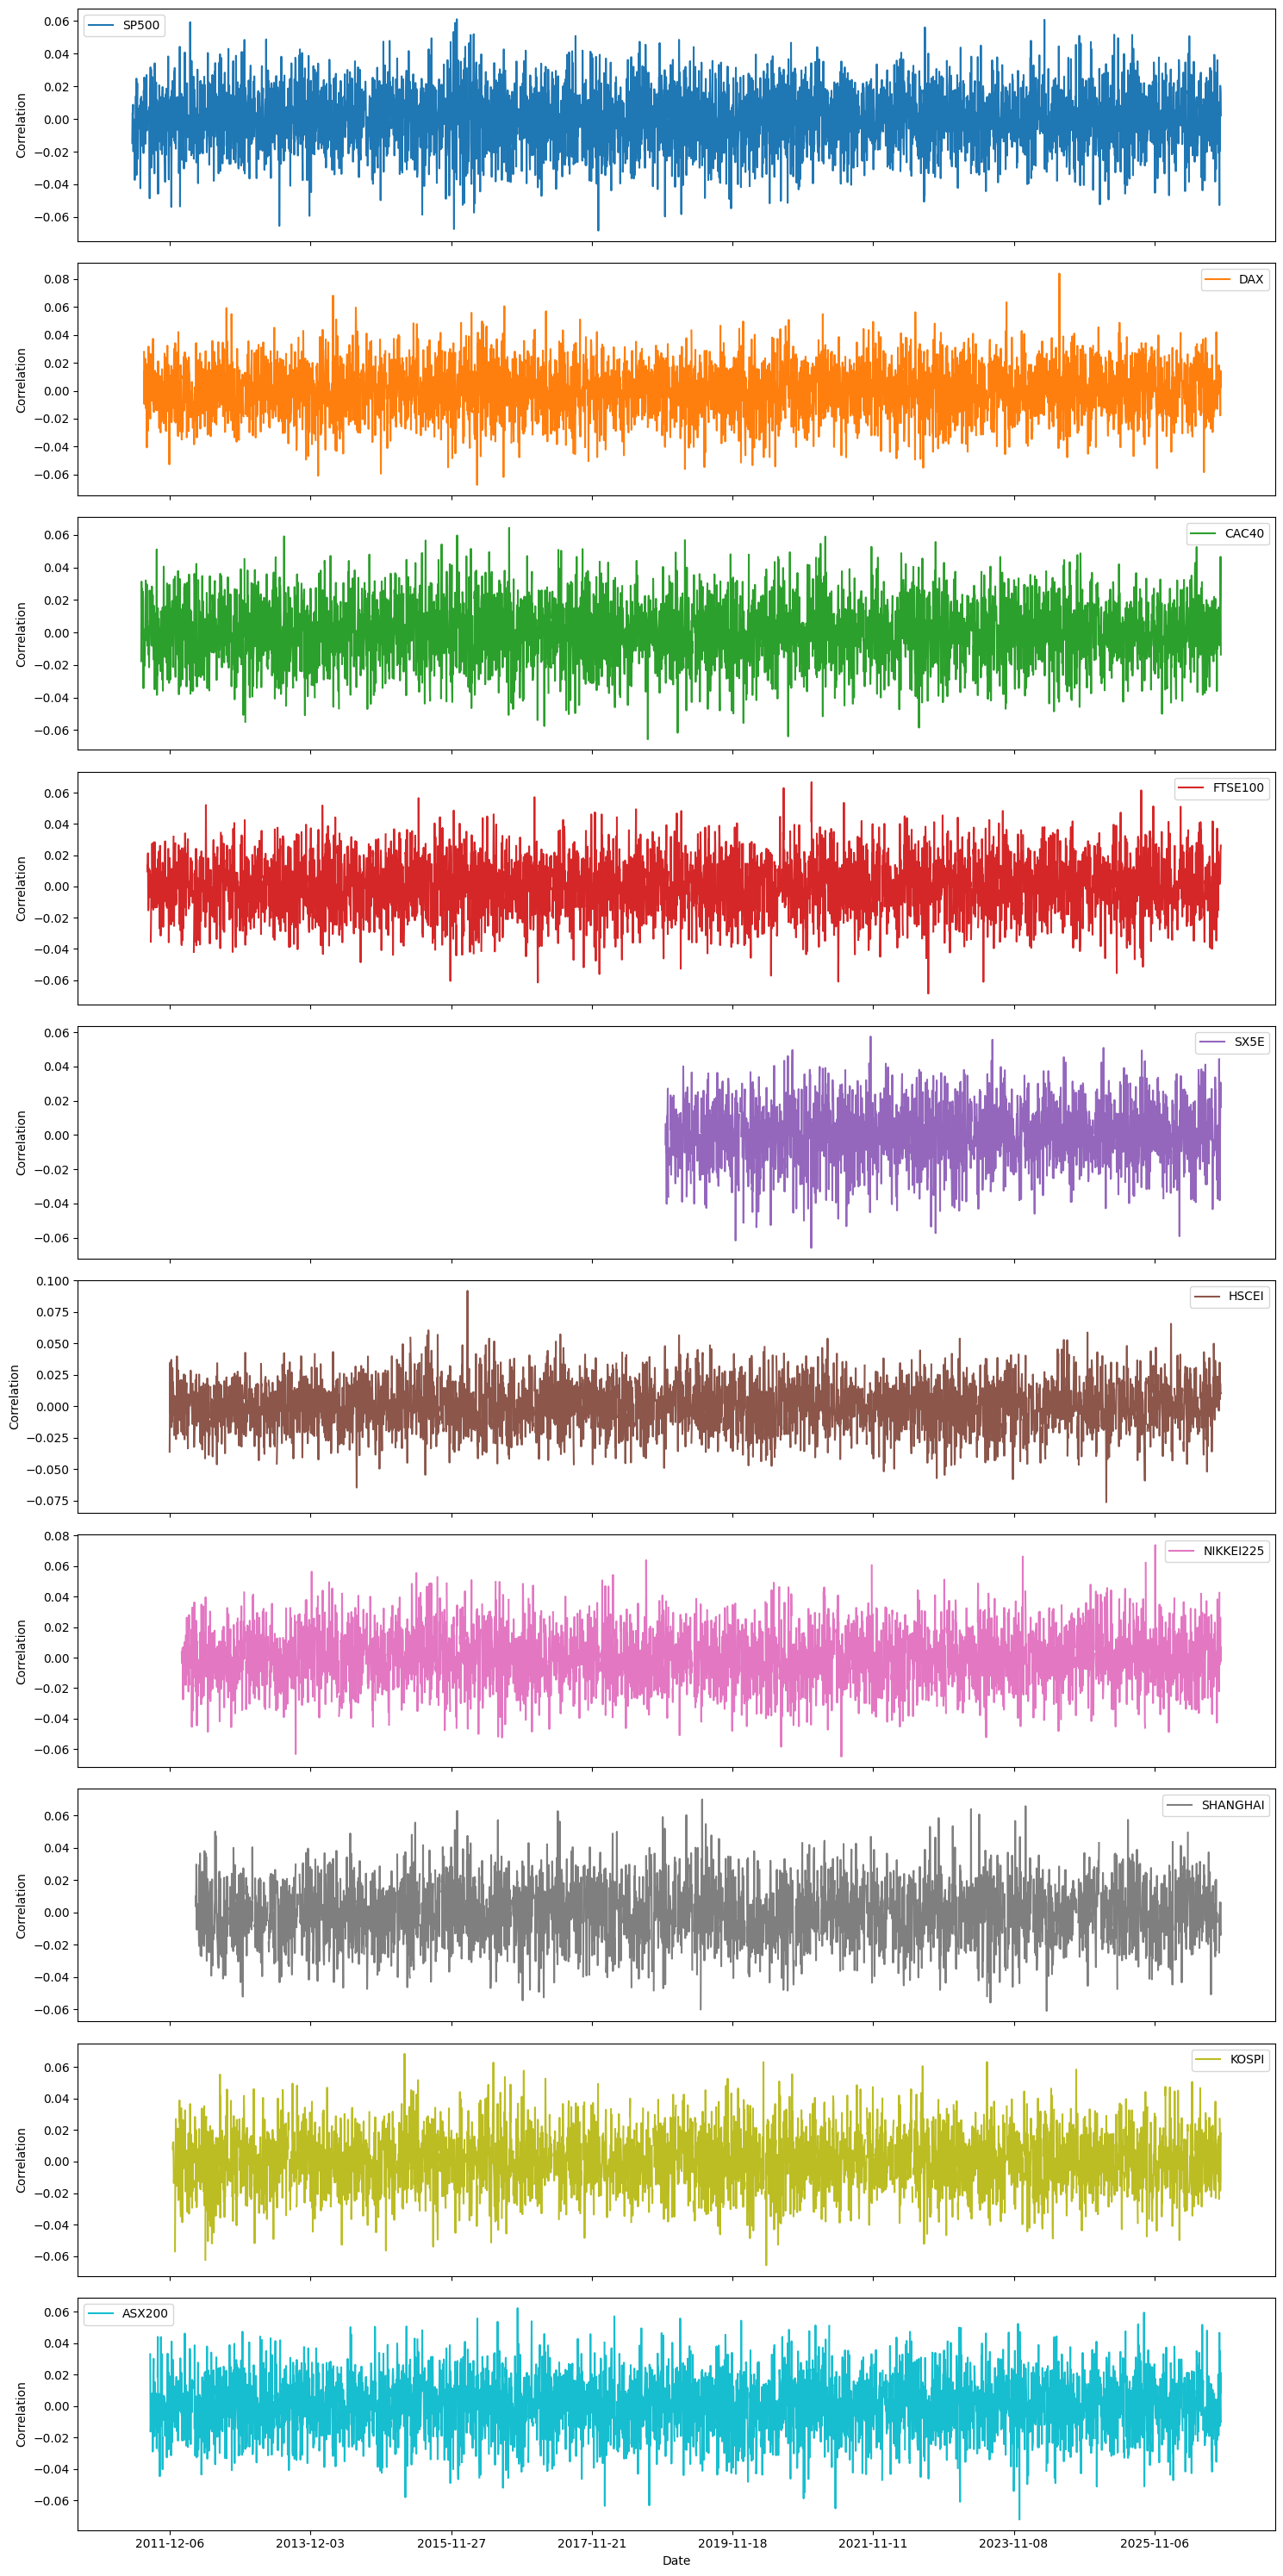

In [98]:
reference = df["RET_1"].to_numpy()

correlations = pd.DataFrame({
    col: market_returns[col].dropna().rolling(len(reference)).apply(
        lambda window: np.corrcoef(reference, window)[0, 1],
        raw=True,
    )
    for col in market_returns.columns
})

correlations.plot(
    subplots=True,
    figsize=(15, 3 * len(correlations.columns)),
    sharex=True,
    ylabel="Correlation",
)
plt.tight_layout()
plt.show()

Adding features

In [16]:
data_handling.add_features(X)

,TS,ALLOCATION,RET_20,RET_19,RET_18,RET_17,RET_16,RET_15,RET_14,RET_13,...,Vol_Momentum_5,Vol_Momentum_20,Vol_Ret_Confirm_1,Vol_Ret_Confirm_5,Signed_Vol_Ratio_5_20,Ret_vs_Group_5,Rank_in_Group_5,Ret_vs_Group_20,Rank_in_Group_20,Vol_vs_Group
ROW_ID,,,,,,,,,,,,,,,,,,,,,
0,DATE_0001,ALLOCATION_01,-0.018192,-0.000306,-0.006881,-0.002393,0.000507,-0.001270,-0.002539,0.002830,...,0.086381,0.613302,NaN,-0.000048,0.140846,0.000512,0.671429,-0.000986,0.100000,0.002844
1,DATE_0001,ALLOCATION_02,-0.006394,-0.001059,0.001565,0.000033,0.002829,0.001725,0.000875,-0.002160,...,-0.794794,-1.801508,NaN,-0.000243,-0.441183,0.000274,0.681818,0.000263,0.727273,0.000615
2,DATE_0001,ALLOCATION_03,-0.016587,-0.004517,-0.005306,0.004314,0.006471,-0.005868,-0.005030,-0.001488,...,0.736525,0.868016,NaN,-0.001467,0.848515,-0.000925,0.228571,-0.001170,0.042857,0.002773
3,DATE_0001,ALLOCATION_04,-0.005344,0.002790,0.006937,-0.004246,-0.005051,-0.000330,-0.000117,-0.005209,...,-0.929260,-0.822900,NaN,0.001590,-1.129251,-0.001496,0.085714,-0.001096,0.057143,0.001469
4,DATE_0001,ALLOCATION_05,-0.010506,-0.005491,0.007752,-0.012299,0.002191,0.003282,0.000495,-0.003489,...,1.278511,0.541321,NaN,-0.001475,2.361838,-0.001185,0.060606,0.000067,0.560606,0.003639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527068,DATE_2522,ALLOCATION_95,-0.000550,0.001751,0.002035,0.005264,0.003387,0.001825,-0.003642,0.001439,...,0.773799,1.015864,NaN,-0.000249,0.761716,-0.000583,0.196970,0.000591,0.863636,0.000518
527069,DATE_2522,ALLOCATION_96,0.003501,-0.004601,-0.001739,-0.000052,0.003670,0.002518,0.006307,0.001633,...,1.244381,0.877332,NaN,0.001047,1.418369,0.000741,0.785714,0.000371,0.814286,0.001035
527070,DATE_2522,ALLOCATION_97,0.005201,0.000580,-0.001607,-0.002955,0.000450,0.004747,0.004622,0.001928,...,1.311624,1.034578,NaN,0.000156,1.267786,0.000019,0.485714,0.000125,0.642857,0.000691


In [17]:
ret_cols = sorted(
    [c for c in X_train.columns if c.startswith("RET_") and c[4:].isdigit()],
    key=lambda c: int(c[4:])
)

allocation_01 = X_train.loc[
    X_train["ALLOCATION"] == "ALLOCATION_01", ret_cols
]

corr_matrix = allocation_01.corr()
display(corr_matrix)

ret_cols = sorted(
    [c for c in X.columns if c.startswith("RET_") and c[4:].isdigit()],
    key=lambda c: int(c[4:])
)
signed_volume_cols = sorted(
    [c for c in X.columns if c.startswith("SIGNED_VOLUME_")],
    key=lambda c: int(c.rsplit("_", 1)[-1])
)

if not signed_volume_cols:
    raise ValueError("Aucune colonne SIGNED_VOLUME_ trouvée.")

allocation_01 = X.loc[
    X["ALLOCATION"] == "ALLOCATION_01",
    ret_cols + signed_volume_cols
]

corr_matrix = allocation_01.corr().loc[ret_cols, signed_volume_cols]
display(corr_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Corrélation entre RET et SIGNED_VOLUME — ALLOCATION_01")
plt.tight_layout()
plt.show()
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Corrélation entre les RET — ALLOCATION_01")
plt.tight_layout()
plt.show()


NameError: name 'X_train' is not defined

Train / Test split

In [18]:
# Trier les dates par leur numéro
dates = sorted(
    X["TS"].unique(),
    key=lambda ts: int(ts.split("_")[1])
)

# Utiliser un historique récent avant la période de validation
n_train_dates = 1000
n_valid_dates = 120

if n_train_dates <= 0 or n_valid_dates <= 0:
    raise ValueError("Les tailles d’entraînement et de validation doivent être positives.")
if len(dates) < n_train_dates + n_valid_dates:
    raise ValueError("Historique insuffisant pour les fenêtres demandées.")

train_dates = dates[-(n_train_dates + n_valid_dates):-n_valid_dates]
valid_dates = dates[-n_valid_dates:]

train_mask = X["TS"].isin(train_dates)
valid_mask = X["TS"].isin(valid_dates)

X_train = X.loc[train_mask].copy()
X_test = X.loc[valid_mask].copy()

Y_train = Y.loc[X_train.index].copy()
Y_train_sign = (Y_train['target']>0).astype(int)
Y_train_sign = pd.DataFrame(Y_train_sign)
Y_test = Y.loc[X_test.index].copy()

Retrieving useful features

In [19]:
# Sélection manuelle des variables pour LightGBM
features_lgbm = [
    'ALLOCATIONS_STD_PERF_20',
    'Ret1_Zscore',
    'ALLOCATIONS_STD_PERF_5',
    'STD_PERF_5',
    'ALLOCATIONS_AVERAGE_PERF_10',
    'Vol_Momentum_20',
    'ALLOCATION',
    'Vol_Ret_Confirm_1',
#    'STD_Perf_20',
    'Momentum_10',
    'Vol_Ratio_5_20'
]

# Ridge utilise uniquement les variables numériques de cette sélection.
features = [feature for feature in features_lgbm if feature != 'ALLOCATION']
features_lgbm


['ALLOCATIONS_STD_PERF_20',
 'Ret1_Zscore',
 'ALLOCATIONS_STD_PERF_5',
 'STD_PERF_5',
 'ALLOCATIONS_AVERAGE_PERF_10',
 'Vol_Momentum_20',
 'ALLOCATION',
 'Vol_Ret_Confirm_1',
 'Momentum_10',
 'Vol_Ratio_5_20']

In [20]:
y_test_vector = (Y_test['target']>0).astype(int)
y_test_vector

,target
ROW_ID,
501413,0
501414,0
501415,0
501416,0
501417,0
...,...
527068,0
527069,1
527070,1


## Pouvoir prédictif de chaque variable seule

Un LightGBM univarié est entraîné pour chaque feature, avec les mêmes paramètres fixes, puis évalué sur la validation temporelle. Il peut apprendre une relation non monotone, sans interaction avec les autres variables. Les catégories natives et les valeurs manquantes sont prises en charge.

Le classement utilise l’AUC de validation : 0,5 correspond à un classement aléatoire et 1 à une séparation parfaite. L’accuracy utilise le seuil fixe de 0,5 et est comparée à une prédiction constante choisie sur l’entraînement. Ces scores dépendent du modèle univarié retenu ; ils ne mesurent pas seulement le meilleur seuil de séparation. Les features dérivées sont évaluées individuellement, même si leur calcul utilise plusieurs colonnes sources.

La validation ne sert ni à l’early stopping ni au réglage des paramètres. Si ce classement sert à sélectionner des features, il faudra une autre période réservée pour évaluer la sélection finale.


Accuracy de référence (classe majoritaire du train) : 52.21%


,auc_validation,accuracy_validation,gain_accuracy_vs_constante
variable,,,
Ret1_Zscore,0.523996,0.522253,0.000156
ALLOCATION,0.511514,0.511535,-0.010561
Vol_Ret_Confirm_1,0.510041,0.520733,-0.001364
Vol_Momentum_20,0.508951,0.520577,-0.001520
ALLOCATIONS_STD_PERF_20,0.507364,0.521707,-0.000390
ALLOCATIONS_AVERAGE_PERF_10,0.506328,0.518940,-0.003157
Momentum_10,0.506147,0.511146,-0.010951
ALLOCATIONS_STD_PERF_5,0.505179,0.513172,-0.008924
Vol_Ratio_5_20,0.504319,0.522330,0.000234


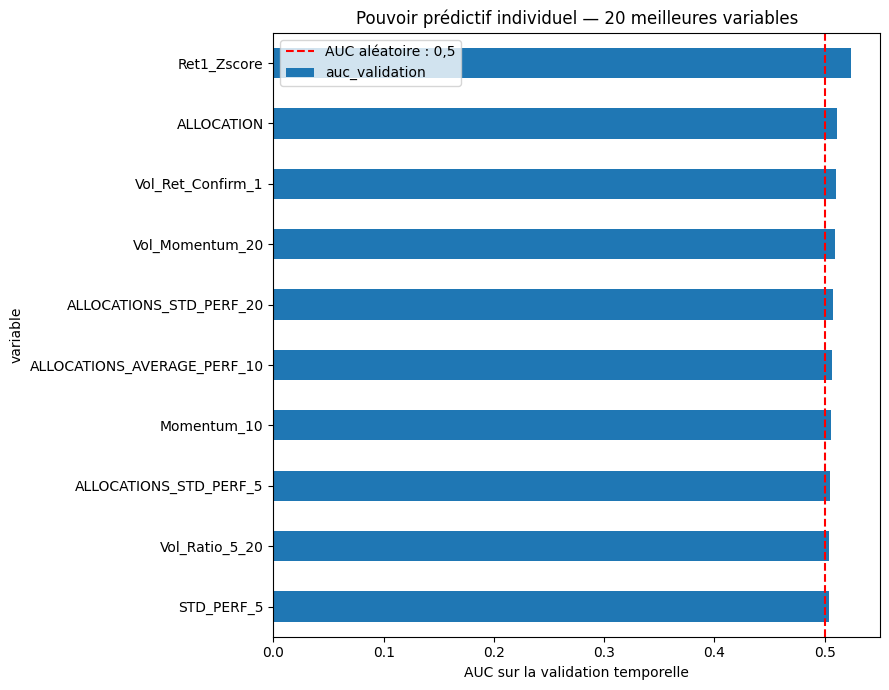

In [21]:
import lightgbm as lgbm
from sklearn.metrics import roc_auc_score, accuracy_score

univariate_y_train = (Y_train.loc[X_train.index, "target"] > 0).astype(int)
univariate_y_valid = (Y_test.loc[X_test.index, "target"] > 0).astype(int)
if univariate_y_train.nunique() < 2 or univariate_y_valid.nunique() < 2:
    raise ValueError("L’entraînement et la validation doivent contenir les deux classes.")

majority_class = int(univariate_y_train.mean() > 0.5)
baseline_accuracy = accuracy_score(
    univariate_y_valid, np.full(len(univariate_y_valid), majority_class)
)

# Paramètres identiques pour toutes les variables, sans réglage sur la validation.
univariate_params = {
    "objective": "binary",
    "verbosity": -1,
    "learning_rate": 0.05,
    "num_leaves": 7,
    "max_depth": 3,
    "min_data_in_leaf": 100,
    "seed": 42,
    "num_threads": 4,
    "deterministic": True,
    "force_col_wise": True,
}
univariate_results = []
for feature in features_lgbm:
    single_feature_model = lgbm.train(
        univariate_params,
        lgbm.Dataset(X_train[[feature]], label=univariate_y_train),
        num_boost_round=100,
    )
    single_feature_proba = single_feature_model.predict(
        X_test[[feature]], num_threads=4
    )
    feature_accuracy = accuracy_score(
        univariate_y_valid, (single_feature_proba > 0.5).astype(int)
    )
    univariate_results.append({
        "variable": feature,
        "auc_validation": roc_auc_score(univariate_y_valid, single_feature_proba),
        "accuracy_validation": feature_accuracy,
        "gain_accuracy_vs_constante": feature_accuracy - baseline_accuracy,
    })

univariate_scores = pd.DataFrame(univariate_results).set_index("variable").sort_values(
    "auc_validation", ascending=False
)
print(f"Accuracy de référence (classe majoritaire du train) : {baseline_accuracy:.2%}")
display(univariate_scores)

ax = univariate_scores.head(20).sort_values("auc_validation")["auc_validation"].plot.barh(
    figsize=(9, 7), title="Pouvoir prédictif individuel — 20 meilleures variables"
)
ax.axvline(0.5, color="red", linestyle="--", label="AUC aléatoire : 0,5")
ax.set_xlabel("AUC sur la validation temporelle")
ax.legend()
plt.tight_layout()
plt.show()


# Training

## Linear Model

In [ ]:
from sklearn import linear_model
new_ridge = linear_model.Ridge(alpha=1)

new_ridge.fit(X_train[features].to_numpy(na_value=0),Y_train.to_numpy(na_value=0))

preds_ridge_df = pd.DataFrame(new_ridge.predict(X_test[features].fillna(0).to_numpy(na_value=0)),columns=['target'])

preds_ridge_vector = (preds_ridge_df>0).astype(int)

In [ ]:
score = accuracy_score(y_test_vector, preds_ridge_vector)
print(f'Ridge Model Accuracy: {score}')

Ridge Model Accuracy: 0.5203819173811379


## LGBM

In [22]:
import lightgbm as lgbm

Model tuning

In [24]:
from utils import k_folds as k

# # 1. Recherche des meilleurs hyperparamètres (mode rapide ~5-10 min)
best_params, study = k.optimize_lgbm(
    X_train, Y_train_sign, features_lgbm,
    n_trials=32,
    num_boost_round=500,          # réduit (early stopping coupe avant)
    early_stopping_rounds=50,     # arrête si pas d'amélioration
    n_splits=6,                   
    subsample_frac=1,           
    num_threads=-1,               # tous les cœurs CPU
)

  0%|          | 0/32 [00:00<?, ?it/s]


✅ Meilleure accuracy OOF : 52.14%
   Meilleurs paramètres   : {'learning_rate': 0.013263619393899086, 'max_depth': 3, 'num_leaves': 121, 'min_child_samples': 455, 'feature_fraction': 0.9550405577601989, 'bagging_fraction': 0.9595275326656388, 'lambda_l1': 0.006037804302325387, 'lambda_l2': 0.013655524160998285}


Model training

In [ ]:
from utils import k_folds as k
models, scores = k.run_lgbm(X_train, Y_train_sign, features_lgbm, best_params)

Fold 1 - Accuracy: 52.01% (best_iter=36)
Fold 2 - Accuracy: 51.82% (best_iter=72)
Fold 3 - Accuracy: 51.71% (best_iter=120)
Fold 4 - Accuracy: 51.46% (best_iter=54)
Fold 5 - Accuracy: 53.31% (best_iter=392)
Fold 6 - Accuracy: 52.24% (best_iter=156)
Accuracy: 52.09% [51.50 ; 52.69] (+- 0.60)


In [ ]:
valid_proba = np.column_stack([
    model.predict(X_test[features_lgbm])
    for model in models
]).mean(axis=1)

score = accuracy_score(
    (Y_test["target"] > 0).astype(int),
    (valid_proba > 0.5).astype(int),
)

print(f"Accuracy sur les 120 dates réservées : {score:.2%}")

Accuracy sur les 120 dates réservées : 52.64%


Formatting and submission

In [ ]:
X_submission = pd.read_csv('data/X_Test.csv', index_col='ROW_ID')
data_handling.add_features(X_submission)

sample_submission = pd.read_csv('data/sample_submission.csv', index_col='ROW_ID')

preds_all = np.column_stack([
    m.predict(X_submission[features_lgbm], num_threads=-1)
    for m in models
])

preds_mean = preds_all.mean(axis=1)

preds_binary = (preds_mean > 0.5).astype(int)

submission = pd.DataFrame(
    preds_binary,
    index=sample_submission.index,
    columns=['target']
)
submission.to_csv('data/submission.csv')
print(f"Submission saved: {submission.shape[0]} rows")
print(f"Distribution: {preds_binary.mean()*100:.1f}% de 1, {(1-preds_binary.mean())*100:.1f}% de 0")
submission.head()